# 03 · Which inputs do the models rely on? Grouped permutation importance (Fig. 5b,c)

In each held-out CRISPR set, the rows of one input group are permuted jointly in the final model's input (20 repeats); importance is the drop in AUPRC. Pair scores are the maximum over a pair's transcript rows, as in the benchmark. 95% CIs: gene-clustered bootstrap with the permuted scores held fixed (500 replicates here).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cislink import datasets, load_model
from cislink import evaluate as ev


def run(cell, m):
    f = datasets.crispr_features(cell); p = datasets.crispr_pairs(cell, score=False)
    model = load_model(m)
    agg = lambda s: p.ID.map(pd.Series(s, index=f.ID.values).groupby(level=0).max()).fillna(0).values
    full, perm = ev.permutation_importance(model.predict, f, p.label.values, aggregate=agg)
    return p, full, perm

out = []
for m in ("e2g", "v2g"):
    p, full, perm = run("K562", m)
    t = ev.importance_table(p.label.values, p.cluster.values, full, perm); t.insert(0, "model", load_model(m).name)
    out.append(t)
    if m == "e2g":
        P, FULL, PERM = p, full, perm
imp = pd.concat(out); imp.round(3)

,model,group,importance,lo,hi
0,CisLink-E2G,accessibility,0.100,0.056,0.139
1,CisLink-E2G,histone marks,0.248,0.190,0.304
2,CisLink-E2G,CTCF,0.012,0.000,0.023
3,CisLink-E2G,expression,0.039,0.011,0.069
4,CisLink-E2G,contact,0.034,0.017,0.050
5,CisLink-E2G,distance and gene context,0.471,0.395,0.531
6,CisLink-E2G,element,-0.007,-0.028,0.019
7,CisLink-E2G,cross-epigenome correlation,0.025,0.011,0.041
0,CisLink-V2G,accessibility,0.294,0.223,0.361
1,CisLink-V2G,histone marks,0.000,-0.000,0.000


## CisLink-E2G by element–TSS distance (held-out K562)

In [2]:
bins = ev.distance_bins(P.distance_to_TSS); rows = []
for lo, hi, b in ev.DISTANCE_BINS:
    t = ev.importance_table(P.label.values, P.cluster.values, FULL, PERM, subset=np.flatnonzero(bins == b)); t.insert(0, "bin", b); rows.append(t)
bd = pd.concat(rows)
pv = bd.pivot(index="group", columns="bin", values="importance")[[b for _, _, b in ev.DISTANCE_BINS]]
pv.round(3)

bin,<10 kb,10-50 kb,50-200 kb,>200 kb
group,,,,
CTCF,0.003,0.018,0.012,-0.009
accessibility,0.069,0.142,0.080,0.045
contact,-0.003,0.032,0.064,0.006
cross-epigenome correlation,0.017,0.029,0.028,0.017
distance and gene context,0.108,0.208,0.306,0.140
element,-0.014,-0.010,-0.021,0.023
expression,-0.002,0.044,0.076,0.013
histone marks,0.113,0.348,0.266,0.113


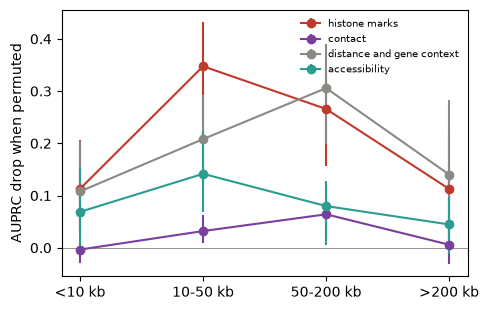

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for g, c in (("histone marks", "#c0392b"), ("contact", "#7a3e9d"), ("distance and gene context", "#8a8984"), ("accessibility", "#2a9d8f")):
    q = bd[bd.group == g].set_index("bin").loc[[b for _, _, b in ev.DISTANCE_BINS]]
    ax.errorbar(range(4), q.importance, yerr=[q.importance - q.lo, q.hi - q.importance], marker="o", label=g, color=c, capsize=0)
ax.set_xticks(range(4)); ax.set_xticklabels([b for _, _, b in ev.DISTANCE_BINS]); ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("AUPRC drop when permuted"); ax.legend(frameon=False, fontsize=7); plt.tight_layout()

Histone marks matter most for pairs 10–200 kb apart, and the cell's Hi-C contact at 50–200 kb. The cross-epigenome correlations add a small, consistent amount at every distance.